<a href="https://colab.research.google.com/github/kvikaee/mobdev/blob/main/ML_1_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Функции (3 балла)

##1.1

Постройте график функции и её производной первого порядка. Также найдите точки экстремума функции, отметьте их на графике другим цветом. Вычисления проведите вручную и приложите скрин расчетов.

$f(x) = (x^2-2x)ln(x)-1.5x^2+4x$


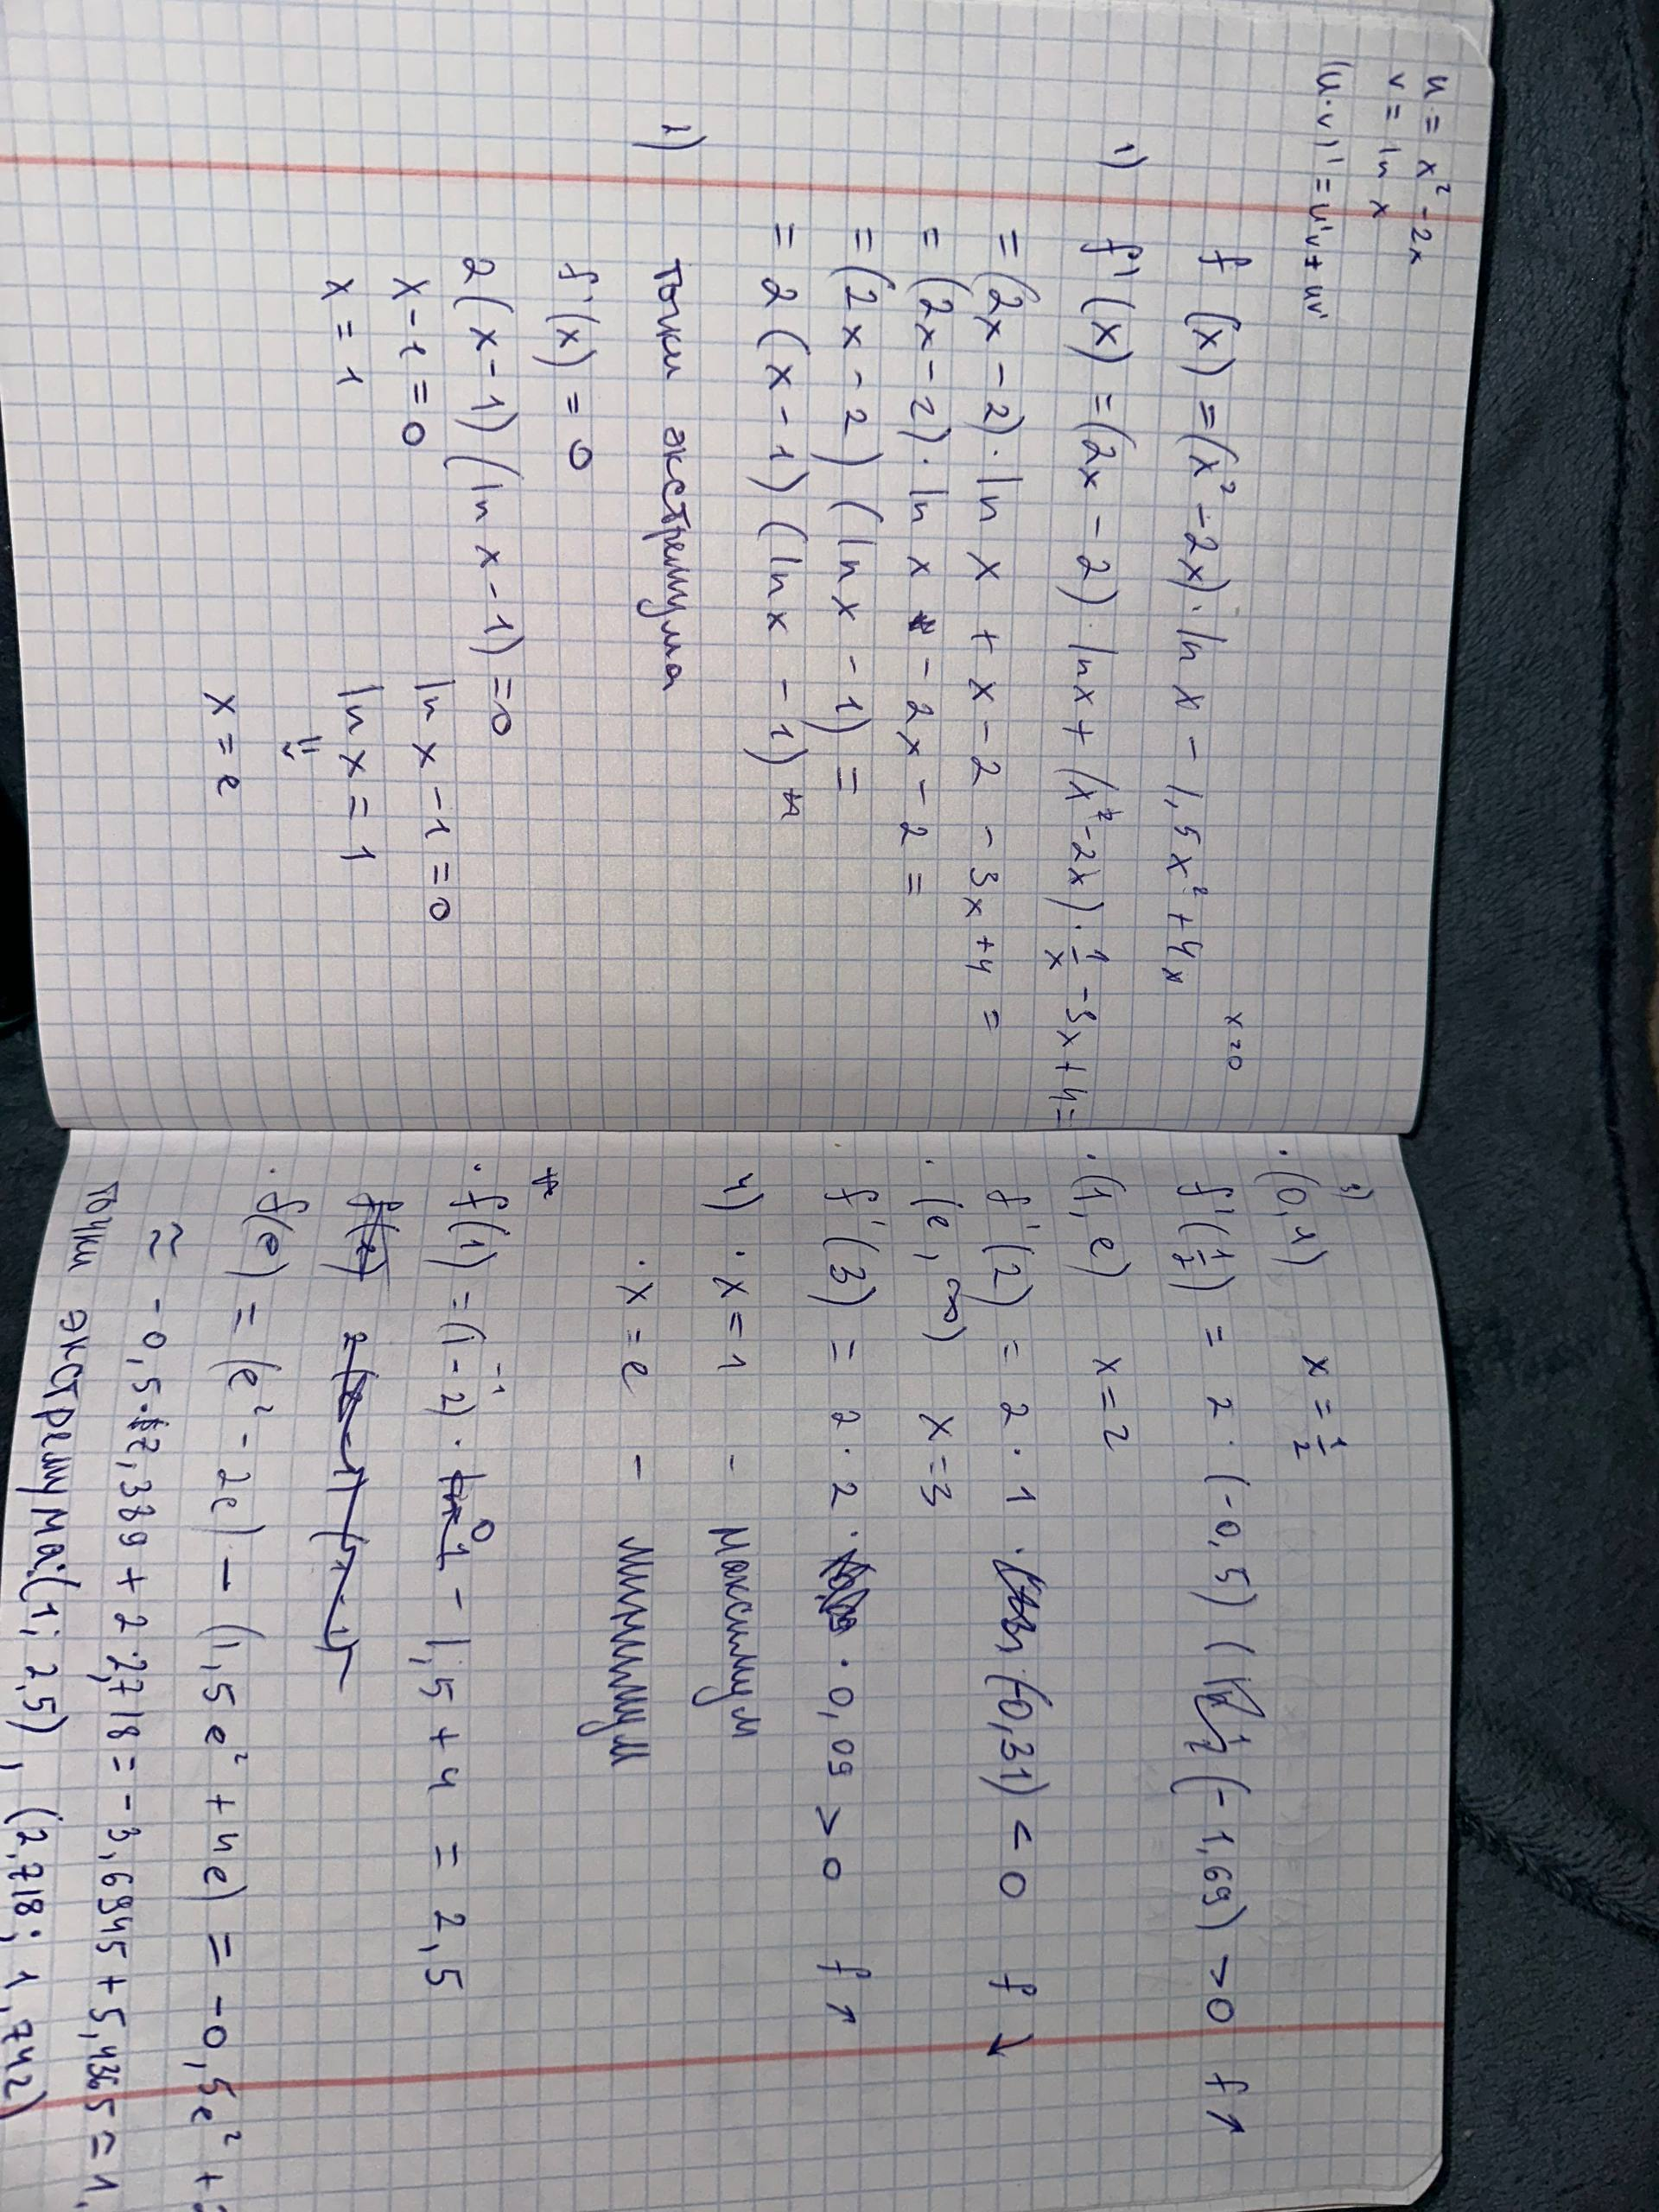

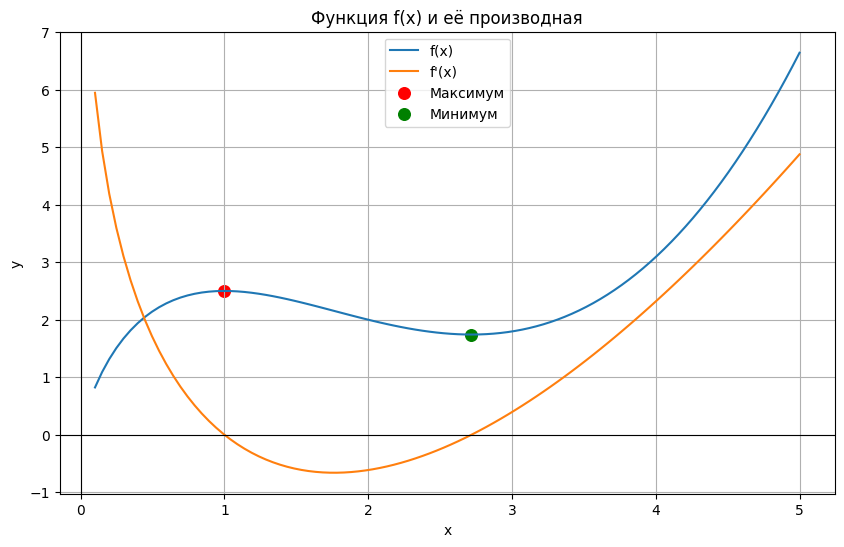

Точка максимума:
x = 1 y = 2.5
Точка минимума:
x = 2.718281828459045 y = 1.742035607452765


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return (x**2 - 2*x) * np.log(x) - 1.5*x**2 + 4*x


def f_dx(x):
    return 2 * (x - 1) * (np.log(x) - 1)


x_values = np.linspace(0.1, 5, 100)

# точки экстремума
x_max = 1
x_min = np.e

y_max = f(x_max)
y_min = f(x_min)

# график функции
plt.figure(figsize=(10, 6))

plt.plot(x_values, f(x_values), label='f(x)')
plt.plot(x_values, f_dx(x_values), label="f'(x)")

# отмечаем точки экстремума
plt.scatter(x_max, y_max, color='red', s=70, label='Максимум')
plt.scatter(x_min, y_min, color='green', s=70, label='Минимум')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Функция f(x) и её производная')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(True)
plt.legend()

plt.show()

print("Точка максимума:")
print("x =", x_max, "y =", y_max)

print("Точка минимума:")
print("x =", x_min, "y =", y_min)

##1.2

Найдите частные производные функции $f(x, y, z) = 15x^2 + exp(x^2 + y^3)*cos(z)$ с помощью [SymPy](https://www.geeksforgeeks.org/python-sympy-diff-method/)

In [ ]:
import sympy as sp

x, y, z = sp.symbols('x y z')

f = 15*x**2 + sp.exp(x**2 + y**3)*sp.cos(z)

df_dx = sp.diff(f, x)
df_dy = sp.diff(f, y)
df_dz = sp.diff(f, z)

print("∂f/∂x =", df_dx)
print("∂f/∂y =", df_dy)
print("∂f/∂z =", df_dz)

∂f/∂x = 2*x*exp(x**2 + y**3)*cos(z) + 30*x
∂f/∂y = 3*y**2*exp(x**2 + y**3)*cos(z)
∂f/∂z = -exp(x**2 + y**3)*sin(z)


##2

Не всегда значения функций возможно рассчитать напрямую, однако их можно вычислить приближенно, используя, например, ряды Тейлора. Реализуйте расчет $e^x$. Сравните значения, получаемые с различной точностью приближения (5, 10, 15), с numpy-реализацией. Постройте график, отобразив на нём все четыре линии.

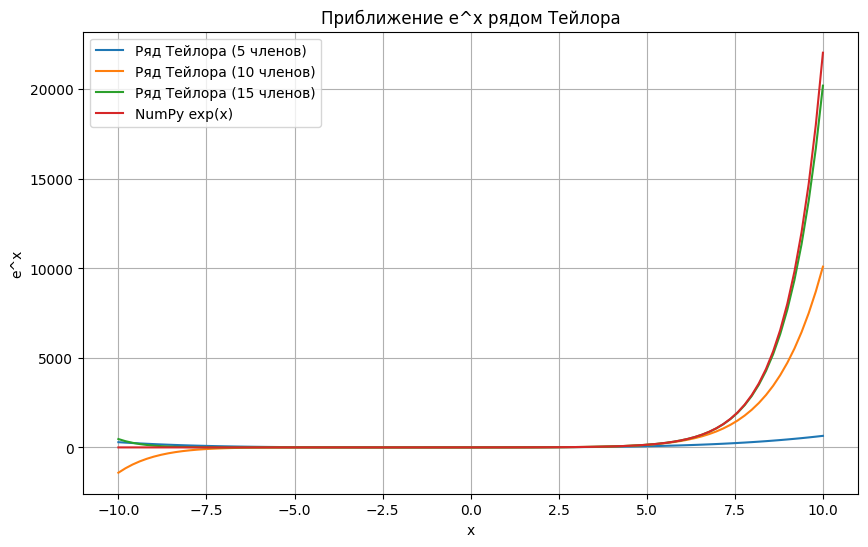

In [ ]:
import math

# значения x
x_values = np.linspace(-10, 10, 100)

# функция для вычисления e^x через ряд Тейлора
def exp_taylor(x, n):
    result = 0
    for k in range(n):
        result += x**k / math.factorial(k)
    return result


# вычисляем приближения
y_5 = exp_taylor(x_values, 5)
y_10 = exp_taylor(x_values, 10)
y_15 = exp_taylor(x_values, 15)

# точное значение через NumPy
y_numpy = np.exp(x_values)


# построение графика
plt.figure(figsize=(10, 6))

plt.plot(x_values, y_5, label='Ряд Тейлора (5 членов)')
plt.plot(x_values, y_10, label='Ряд Тейлора (10 членов)')
plt.plot(x_values, y_15, label='Ряд Тейлора (15 членов)')
plt.plot(x_values, y_numpy, label='NumPy exp(x)')

plt.xlabel('x')
plt.ylabel('e^x')
plt.title('Приближение e^x рядом Тейлора')
plt.legend()
plt.grid(True)

plt.show()

##3

Рассмотрите две следующие функции, часто использующиеся как функции потерь (то есть они помогают оценить качество предсказаний модели).

$MAE (Mean\ Absolute\ Error) = \frac{1}{n} \sum_{i=1}^{n} |y_i - \widehat{y}_i|$

$MSE (Mean\ Squared\ Error) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \widehat{y}_i)^2$

Письменно ответьте на вопросы:

1. Какая проблема присуща MAE с точки зрения дифференцирования?

2. Если в качестве $\widehat{y}_i$ всегда будет предсказываться константное значение, каким оно должно быть, чтобы минимизировать значение каждой из функций?


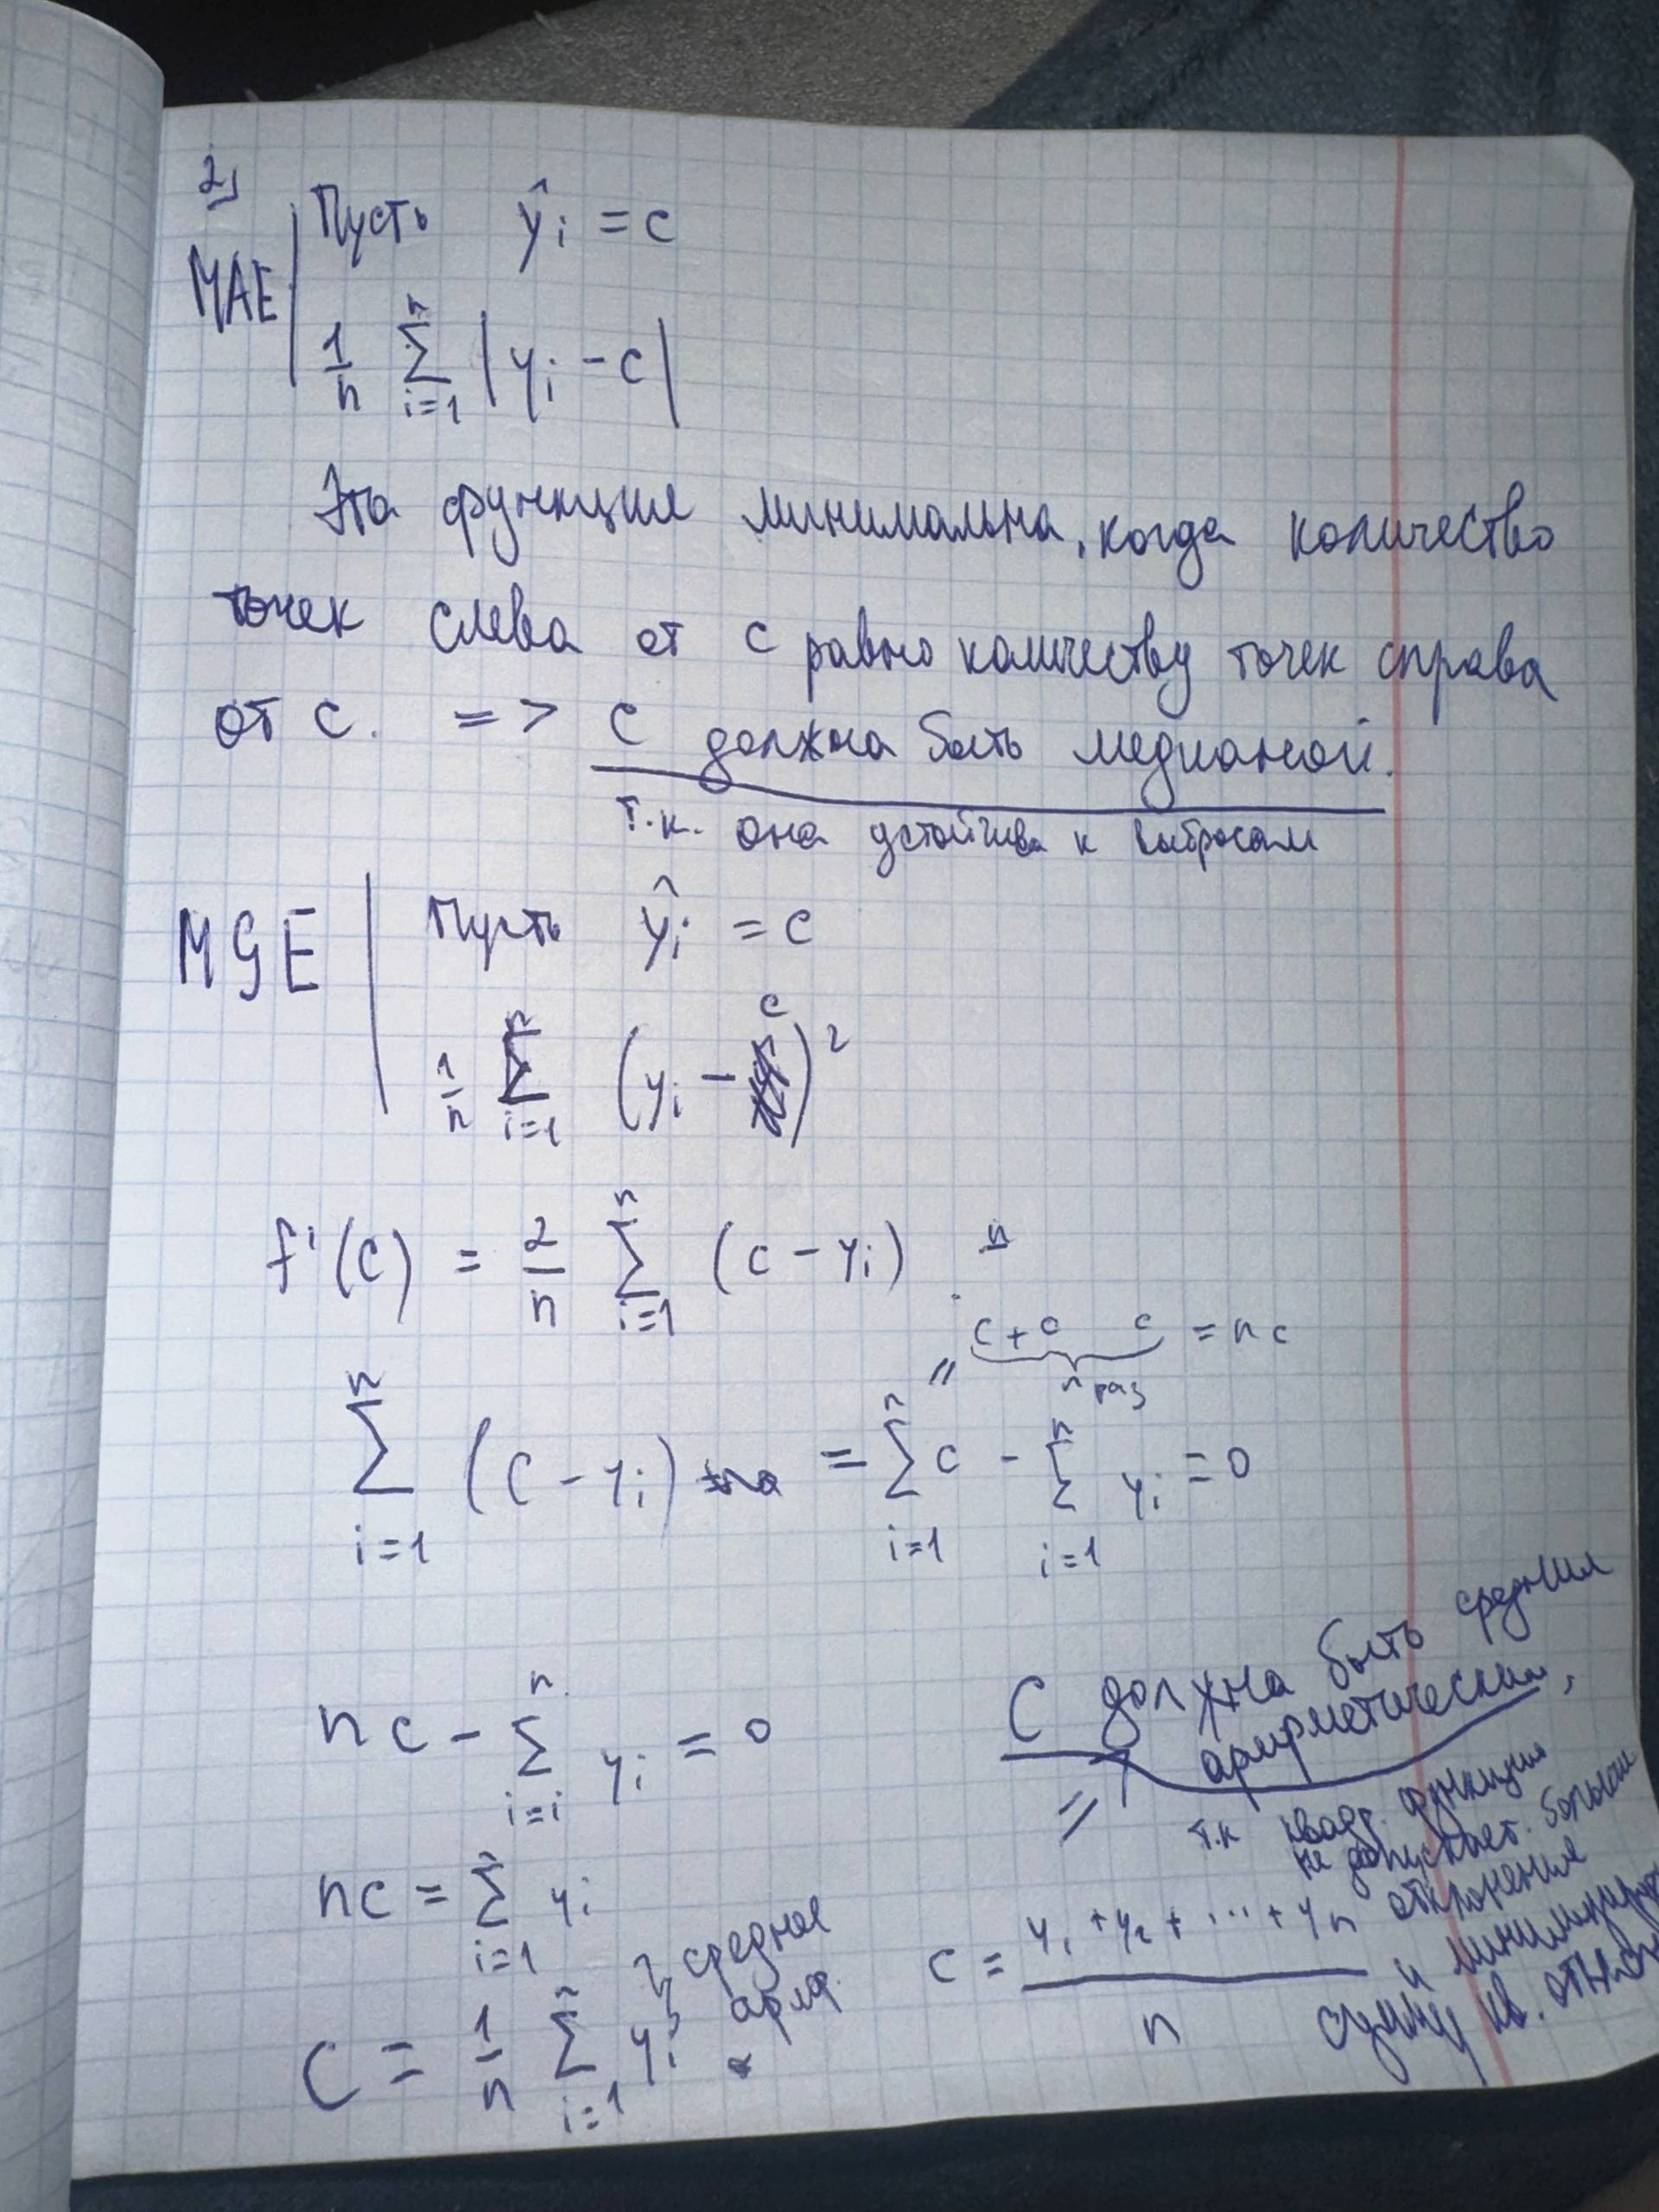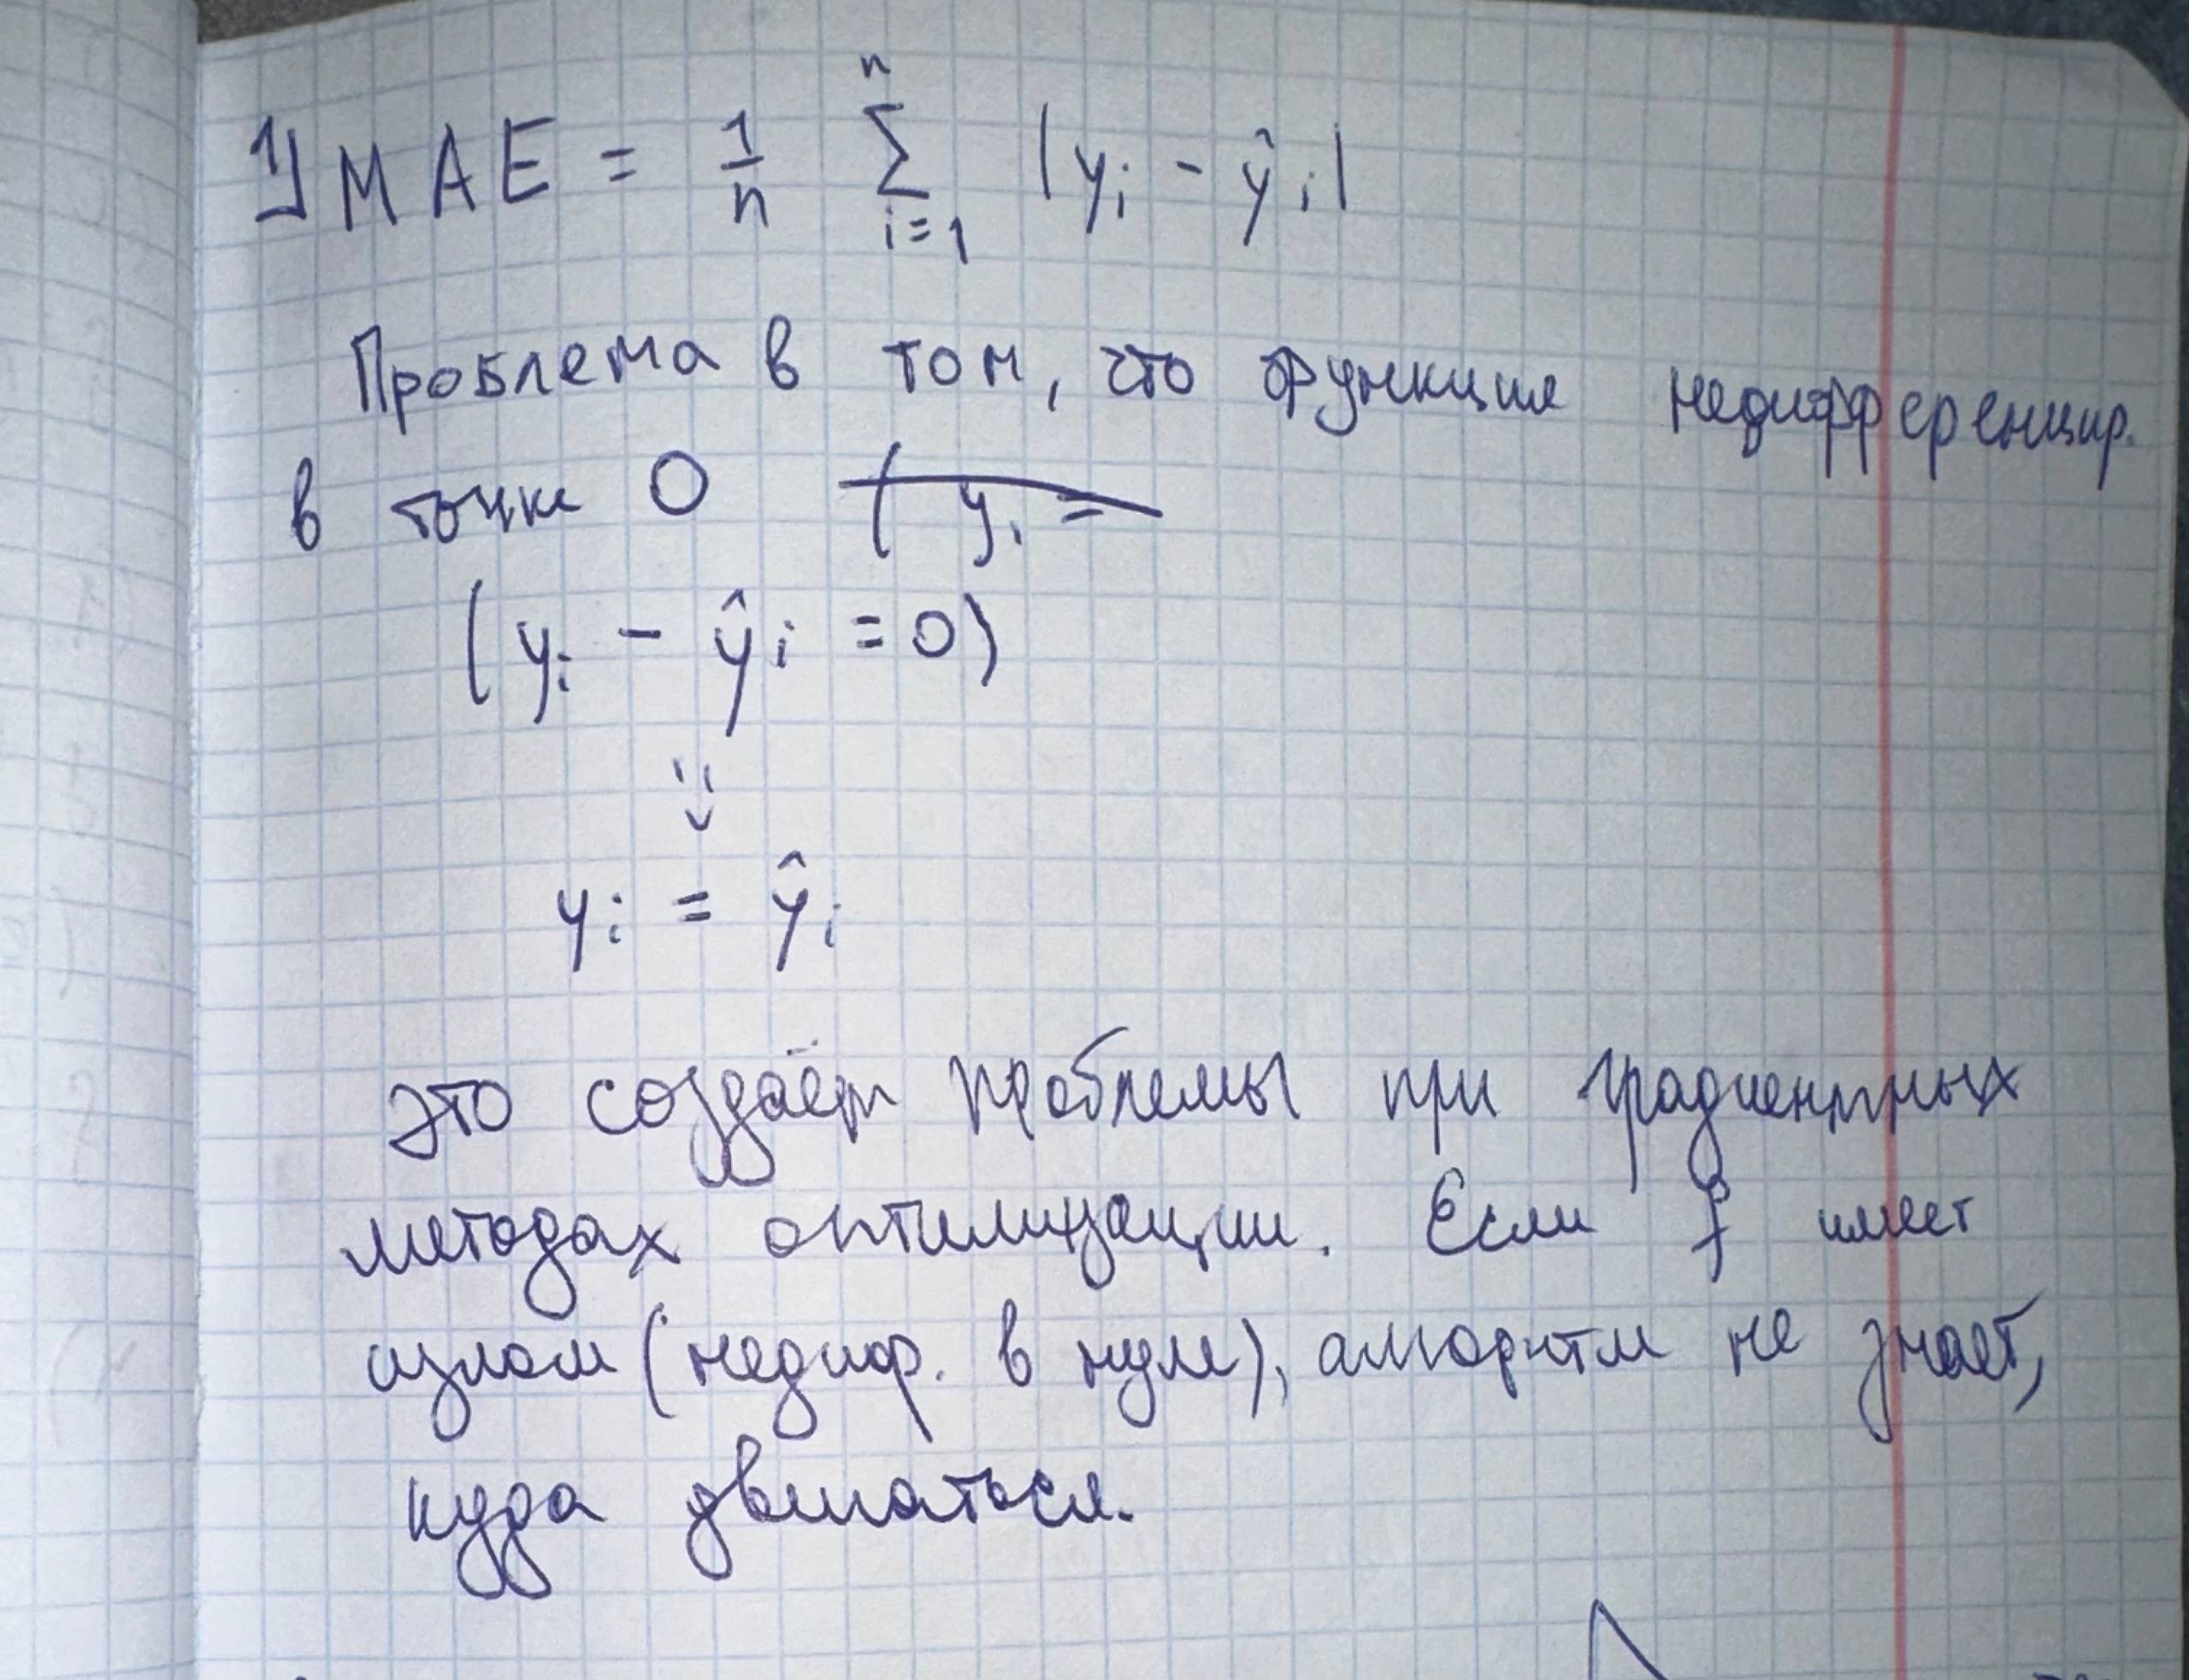

# Матрицы. Векторы (2 балла)

##1

Реализуйте следующие паттерны. Не используйте циклы! Все матрицы квадратные со стороной длины n. Примеры приведены для n=5.

1. Шахматная доска
```
[[0. 1. 0. 1. 0.]
 [1. 0. 1. 0. 1.]
 [0. 1. 0. 1. 0.]
 [1. 0. 1. 0. 1.]
 [0. 1. 0. 1. 0.]]
 ```
2. Полоса шириной 3 относительно главной диагонали
```
[[1. 1. 0. 0. 0.]
 [1. 1. 1. 0. 0.]
 [0. 1. 1. 1. 0.]
 [0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1.]]
 ```
3. Кайма из единиц
```
[[1. 1. 1. 1. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 1. 1. 1. 1.]]
 ```
4. Полосы
```
[[0. 0. 0. 0. 0.]
 [1. 1. 1. 1. 1.]
 [0. 0. 0. 0. 0.]
 [1. 1. 1. 1. 1.]
 [0. 0. 0. 0. 0.]]
 ```
5. Верхний треугольник
```
[[1. 1. 1. 1. 1.]
 [0. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 0. 1.]]
 ```


In [ ]:
n = 5

# 1. шахматная доска
chess = np.indices((n, n)).,) % 2
print("1. Шахматная доска:")
print(chess)

# 2. полоса шириной 3 относительно главной диагонали
i, j = np.indices((n, n))
band = (np.abs(i - j) <= 1).astype(float)
print("\n2. Полоса:")
print(band)

# 3. кайма из единиц
border = np.zeros((n, n))
border[0, :] = 1
border[-1, :] = 1
border[:, 0] = 1
border[:, -1] = 1
print("\n3. Кайма:")
print(border)

# 4. полосы
stripes = np.indices((n, n))[0] % 2
print("\n4. Полосы:")
print(stripes)

# 5. верхний треугольник
upper = np.triu(np.ones((n, n)))
print("\n5. Верхний треугольник:")
print(upper)

1. Шахматная доска:
[[0 1 0 1 0]
 [1 0 1 0 1]
 [0 1 0 1 0]
 [1 0 1 0 1]
 [0 1 0 1 0]]

2. Полоса:
[[1. 1. 0. 0. 0.]
 [1. 1. 1. 0. 0.]
 [0. 1. 1. 1. 0.]
 [0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1.]]

3. Кайма:
[[1. 1. 1. 1. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 1. 1. 1. 1.]]

4. Полосы:
[[0 0 0 0 0]
 [1 1 1 1 1]
 [0 0 0 0 0]
 [1 1 1 1 1]
 [0 0 0 0 0]]

5. Верхний треугольник:
[[1. 1. 1. 1. 1.]
 [0. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 0. 1.]]


##2

Пусть дан вектор следующего вида. Преобразуйте его, чтобы получить две матрицы: первая должна содержать одинаковые значения column-wise (столбец целиком из нулей, столбец целиком из единиц и так далее), а вторая - row-wise. Не используйте циклы.

In [ ]:
n = 5
vector = np.hstack([[i for i in range(n)] for _ in range(n)])  # также существуют vstack и dstack
print(vector)

[0 1 2 3 4 0 1 2 3 4 0 1 2 3 4 0 1 2 3 4 0 1 2 3 4]


In [ ]:
# column-wise
column_wise = vector.reshape(n, n)

# row-wise
row_wise = vector.reshape(n, n).T


print("\ncolumn-wise:")
print(column_wise)

print("\nrow-wise:")
print(row_wise)


column-wise:
[[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]]

row-wise:
[[0 0 0 0 0]
 [1 1 1 1 1]
 [2 2 2 2 2]
 [3 3 3 3 3]
 [4 4 4 4 4]]


# Введение в PyTorch (2 балла)

С точки зрения синтаксиса PyTorch похож на NumPy, основная разница заключается в том, что данный фреймворк предназначен для автоматического расчета градиентов. [Вот тут](https://github.com/torch/torch7/wiki/Torch-for-Numpy-users) можно почитать про то, как соотносятся две эти библиотеки.

[Неплохой курс чисто про PyTorch](https://www.learnpytorch.io/)

[Документация PyTorch](https://pytorch.org/)

In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision.transforms import transforms

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

##1

1. Создайте два вещественных тензора: $a$ размером (10, 2) и $b$ размером (, 20)

2. Создайте тензор c, являющийся тензором $b$, но размера (2, 2, 5)

3. Выведите первый столбец матрицы $a$ с помощью индексации

4. Создайте тензор $d$, являющийся тензором $b$, но размера (10, 2). Произведите все арифметические операции с тензорами $a$ и $d$

In [ ]:
# создаём вещественные тензоры
a = torch.randn(10, 2)
b = torch.randn(20)

print("a:")
print(a)
print("Размер a:", a.shape)

print("\nb:")
print(b)
print("Размер b:", b.shape)


# меняем форму b: (20,) - (2, 2, 5)
c = b.reshape(2, 2, 5)

print("\nc:")
print(c)
print("Размер c:", c.shape)


# выводим первый столбец матрицы a
first_column = a[:, 0]

print("\nПервый столбец a:")
print(first_column)


# меняем форму b: (20,) - (10, 2)
d = b.reshape(10, 2)

print("\nd:")
print(d)
print("Размер d:", d.shape)


# арифметические операции с a и d
print("\nСложение:")
print(a + d)

print("\nВычитание:")
print(a - d)

print("\nУмножение:")
print(a * d)

print("\nДеление:")
print(a / d)

a:
tensor([[-0.2708,  1.1199],
        [-2.0828, -0.7583],
        [ 2.1974, -1.0198],
        [ 0.6734, -0.6377],
        [-1.4370, -0.3446],
        [-1.6541,  1.2669],
        [-0.3887, -2.0625],
        [ 2.2413, -0.1666],
        [ 0.4026, -0.5285],
        [ 0.5345, -0.1126]])
Размер a: torch.Size([10, 2])

b:
tensor([-0.3754,  0.3425,  0.1595, -0.9297,  1.0978, -2.9011,  0.7165,  1.1958,
         1.3100,  0.7617, -0.7380, -1.3835, -0.1620, -0.4715,  0.5359,  0.8518,
         1.0898, -1.1285, -1.4204,  2.5135])
Размер b: torch.Size([20])

c:
tensor([[[-0.3754,  0.3425,  0.1595, -0.9297,  1.0978],
         [-2.9011,  0.7165,  1.1958,  1.3100,  0.7617]],

        [[-0.7380, -1.3835, -0.1620, -0.4715,  0.5359],
         [ 0.8518,  1.0898, -1.1285, -1.4204,  2.5135]]])
Размер c: torch.Size([2, 2, 5])

Первый столбец a:
tensor([-0.2708, -2.0828,  2.1974,  0.6734, -1.4370, -1.6541, -0.3887,  2.2413,
         0.4026,  0.5345])

d:
tensor([[-0.3754,  0.3425],
        [ 0.1595, -0.9297],


## 2

1. Создайте тензор *целых чисел* `images` размерности (100, 200, 200, 3) (можно интерпретировать это как 100 картинок размера 200х200 с тремя цветовыми каналами, то есть 100 цветных изображений 200х200). Заполните его нулями  

2. Сделайте так, чтобы у $i$-ой по порядку картинки была нарисована белая полоса толщиной два пикселя в строках, которые соответствуют номеру картинки * 2. Например, у 3-ей по порядку картинки белая полоска будет занимать 6 и 7 строки, у 99 - 198 и 199. Сделать белую строку можно, записав в ячейки тензора число 255 (по всем трём каналам). Выведите несколько примеров с помощью `pyplot`  

3. Посчитайте среднее тензора `images` по 1-ой оси (по сути - средняя картинка), умножьте полученный тензор на 70. Нарисуйте с помощью `pyplot`, должна получиться серая картинка (при взятии среднего нужно привести тензор к float с помощью `.float()`, при отрисовке обратно к int с помощью `.int()`)

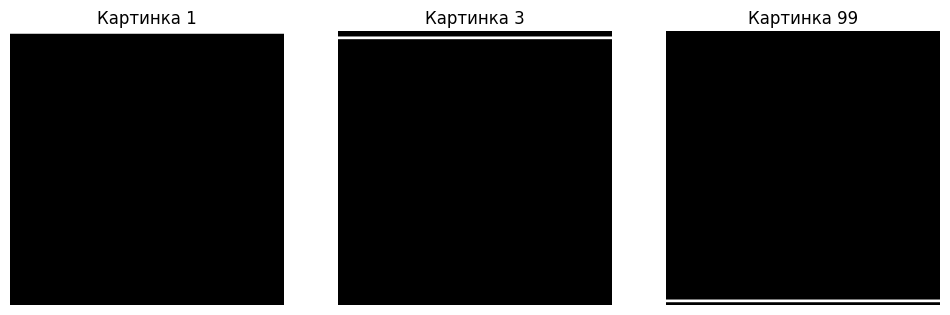

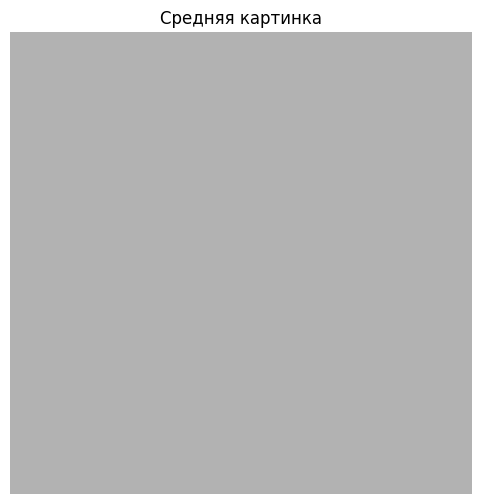

In [ ]:
# создаём тензор из 100 изображений 200x200 с 3 каналами
images = torch.zeros(100, 200, 200, 3, dtype=torch.int32)

# для каждой картинки создаём белую полоску толщиной 2 пикселя
for i in range(100):
    row = i * 2
    images[i, row:row + 2, :, :] = 255

# выводим несколько примеров
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(images[0])
plt.title("Картинка 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(images[2])
plt.title("Картинка 3")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(images[98])
plt.title("Картинка 99")
plt.axis("off")

plt.show()


# считаем среднюю картинку по первой оси
mean_image = images.float().mean(dim=0)

# умножаем среднюю картинку на 70
mean_image = mean_image * 70

# переводим обратно в целые числа
mean_image = mean_image.int()

# выводим среднюю картинку
plt.figure(figsize=(6, 6))
plt.imshow(mean_image)
plt.title("Средняя картинка")
plt.axis("off")
plt.show()

## 3

1. Смените среду выполнения на GPU (в Colab нажмите в меню сверху: `Runtime` -> `Change Runtime Type` -> `GPU`, где изначально стоит `None` (`Среда выполнение` - `Сменить среду выполнения`))

2. Объявите тензор $a$ размера (2, 3, 4) и тензор $b$ размера (1, 8, 3) на GPU, иницилизируйте их случайно равномерно (`.uniform_()`)

3. Измените форму тензора $b$, чтобы она совпадала с формой тензора $a$, получите тензор $c$.

4. Переместите тензоры $a$ и $c$ на CPU.

5. Объявите тензор `L = torch.mean((c - a) `**` 2)` и посчитайте градиент $L$ по $c$ ( то есть $\frac{\partial{L}}{\partial{c}})$. Выведите градиент $L$ по $c$. Также вычислите его вручную, чтобы проверить себя.

In [ ]:
import torch

# создаём тензор a размера (2, 3, 4) на GPU
a = torch.empty(2, 3, 4, device=device)
a.uniform_()

# создаём тензор b размера (1, 8, 3) на GPU
b = torch.empty(1, 8, 3, device=device)
b.uniform_()

print("Размер a:", a.shape)
print("Размер b:", b.shape)


# изменяем форму b: (1, 8, 3) - (2, 3, 4)
c = b.reshape(2, 3, 4)

print("Размер c:", c.shape)


# перемещаем a и c на CPU
a = a.cpu()
c = c.cpu()

print("Устройство a:", a.device)
print("Устройство c:", c.device)


# включаем отслеживание градиента для c
c.requires_grad_(True)

# вычисляем функцию потерь
L = torch.mean((c - a) ** 2)

# вычисляем градиент L по c
L.backward()

print("\nL =", L)
print("\nГрадиент L по c:")
print(c.grad)

Устройство: cuda
Размер a: torch.Size([2, 3, 4])
Размер b: torch.Size([1, 8, 3])
Размер c: torch.Size([2, 3, 4])
Устройство a: cpu
Устройство c: cpu

L = tensor(0.1278, grad_fn=<MeanBackward0>)

Градиент L по c:
tensor([[[-0.0349, -0.0342, -0.0359, -0.0032],
         [ 0.0183, -0.0160,  0.0317,  0.0213],
         [ 0.0147, -0.0193, -0.0518, -0.0022]],

        [[-0.0034,  0.0218, -0.0036,  0.0027],
         [ 0.0168, -0.0218, -0.0460, -0.0669],
         [-0.0026, -0.0109, -0.0332, -0.0567]]])


In [ ]:
manual_grad = 2 * (c - a) / c.numel()

print("\nГрадиент вручную:")
print(manual_grad)


Градиент вручную:
tensor([[[-0.0349, -0.0342, -0.0359, -0.0032],
         [ 0.0183, -0.0160,  0.0317,  0.0213],
         [ 0.0147, -0.0193, -0.0518, -0.0022]],

        [[-0.0034,  0.0218, -0.0036,  0.0027],
         [ 0.0168, -0.0218, -0.0460, -0.0669],
         [-0.0026, -0.0109, -0.0332, -0.0567]]], grad_fn=<DivBackward0>)


# Теория вероятностей (4 балла)

##1

Постройте графики плотности распределений для следующих распределений:

* Биномиальное распределение
* Геометрическое распределение
* Равномерное распределение
* Нормальное распределение
* Логнормальное распределение

Параметры распределений выберите произвольно. Подумайте, какие явления в реальном мире подчиняются тому или иному распределению.

Отобразите также следующие статистические показатели: выборочное среднее, мода, медиана, стандартное отклонение.

In [ ]:
from scipy import stats

n = 1000

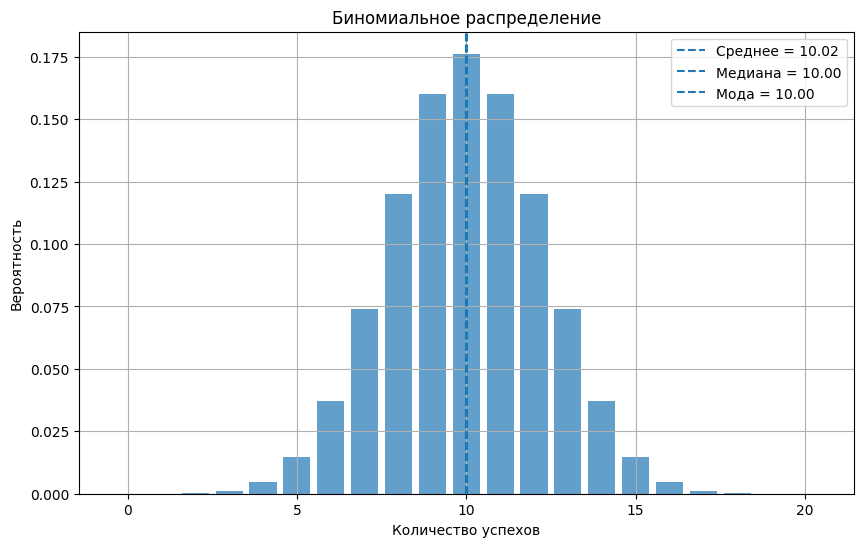

Среднее: 10.017
Мода: 10
Медиана: 10.0
Стандартное отклонение: 2.190596037611682


In [ ]:
# биномианальное распределние

binomial_n = 20
binomial_p = 0.5

binomial_data = np.random.binomial(
    binomial_n,
    binomial_p,
    n
)

binomial_mean = np.mean(binomial_data)
binomial_median = np.median(binomial_data)
binomial_std = np.std(binomial_data)
binomial_mode = stats.mode(
    binomial_data,
    keepdims=True
).mode[0]

x_binomial = np.arange(0, binomial_n + 1)

y_binomial = stats.binom.pmf(
    x_binomial,
    binomial_n,
    binomial_p
)

plt.figure(figsize=(10, 6))

plt.bar(
    x_binomial,
    y_binomial,
    alpha=0.7
)

plt.axvline(
    binomial_mean,
    linestyle='--',
    label=f'Среднее = {binomial_mean:.2f}'
)

plt.axvline(
    binomial_median,
    linestyle='--',
    label=f'Медиана = {binomial_median:.2f}'
)

plt.axvline(
    binomial_mode,
    linestyle='--',
    label=f'Мода = {binomial_mode:.2f}'
)

plt.title('Биномиальное распределение')
plt.xlabel('Количество успехов')
plt.ylabel('Вероятность')
plt.legend()
plt.grid(True)

plt.show()

print('Среднее:', binomial_mean)
print('Мода:', binomial_mode)
print('Медиана:', binomial_median)
print('Стандартное отклонение:', binomial_std)

Распределение показывает количество успехов в фиксированном числе испытаний. Большинство значений находится около среднего, а вероятность крайних значений небольшая.

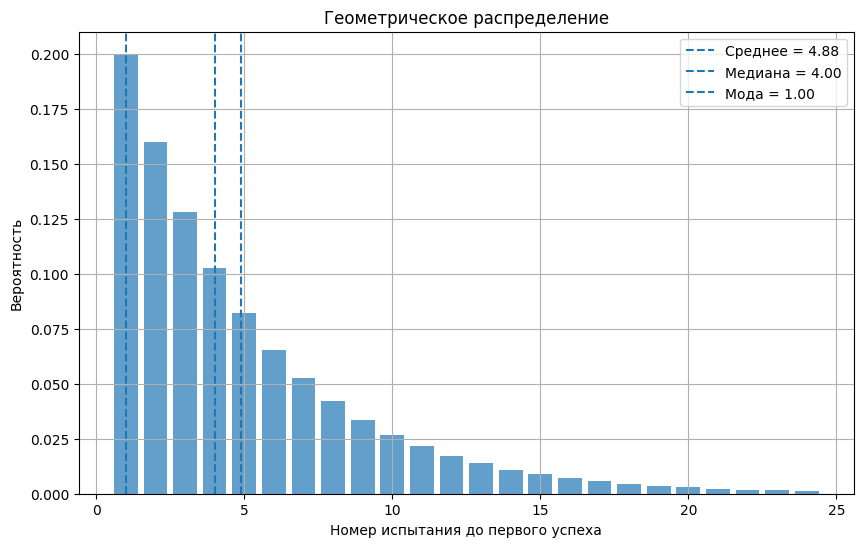

Среднее: 4.884
Мода: 1
Медиана: 4.0
Стандартное отклонение: 4.207201445141414


In [ ]:
# геометрическое распределение

geometric_p = 0.2

geometric_data = np.random.geometric(
    geometric_p,
    n
)

geometric_mean = np.mean(geometric_data)
geometric_median = np.median(geometric_data)
geometric_std = np.std(geometric_data)

geometric_mode = stats.mode(
    geometric_data,
    keepdims=True
).mode[0]

x_geometric = np.arange(1, 25)

y_geometric = stats.geom.pmf(
    x_geometric,
    geometric_p
)

plt.figure(figsize=(10, 6))

plt.bar(
    x_geometric,
    y_geometric,
    alpha=0.7
)

plt.axvline(
    geometric_mean,
    linestyle='--',
    label=f'Среднее = {geometric_mean:.2f}'
)

plt.axvline(
    geometric_median,
    linestyle='--',
    label=f'Медиана = {geometric_median:.2f}'
)

plt.axvline(
    geometric_mode,
    linestyle='--',
    label=f'Мода = {geometric_mode:.2f}'
)

plt.title('Геометрическое распределение')
plt.xlabel('Номер испытания до первого успеха')
plt.ylabel('Вероятность')
plt.legend()
plt.grid(True)

plt.show()

print('Среднее:', geometric_mean)
print('Мода:', geometric_mode)
print('Медиана:', geometric_median)
print('Стандартное отклонение:', geometric_std)

Большая часть значений сосредоточена около первых испытаний. С увеличением количества попыток вероятность постепенно уменьшается.

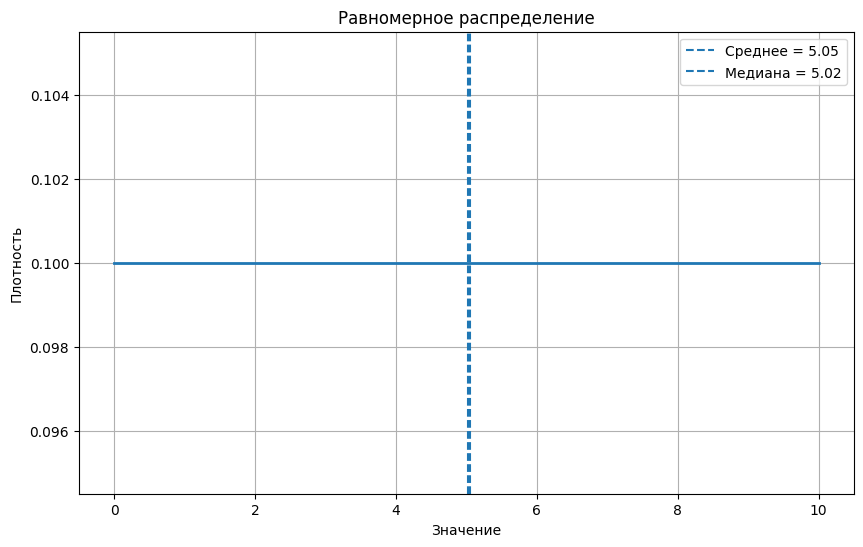

Среднее: 5.050452451399559
Мода: нет единственной моды
Медиана: 5.023481351055956
Стандартное отклонение: 2.9240036136180554


In [ ]:
# равномерное распределение
uniform_a = 0
uniform_b = 10

uniform_data = np.random.uniform(
    uniform_a,
    uniform_b,
    n
)

uniform_mean = np.mean(uniform_data)
uniform_median = np.median(uniform_data)
uniform_std = np.std(uniform_data)

x_uniform = np.linspace(
    uniform_a,
    uniform_b,
    500
)

y_uniform = stats.uniform.pdf(
    x_uniform,
    loc=uniform_a,
    scale=uniform_b - uniform_a
)

plt.figure(figsize=(10, 6))

plt.plot(
    x_uniform,
    y_uniform,
    linewidth=2
)

plt.axvline(
    uniform_mean,
    linestyle='--',
    label=f'Среднее = {uniform_mean:.2f}'
)

plt.axvline(
    uniform_median,
    linestyle='--',
    label=f'Медиана = {uniform_median:.2f}'
)

plt.title('Равномерное распределение')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)

plt.show()

print('Среднее:', uniform_mean)
print('Мода: нет единственной моды')
print('Медиана:', uniform_median)
print('Стандартное отклонение:', uniform_std)

Все значения в заданном интервале имеют примерно одинаковую вероятность. Поэтому график имеет практически постоянную плотность, а единственной моды нет.

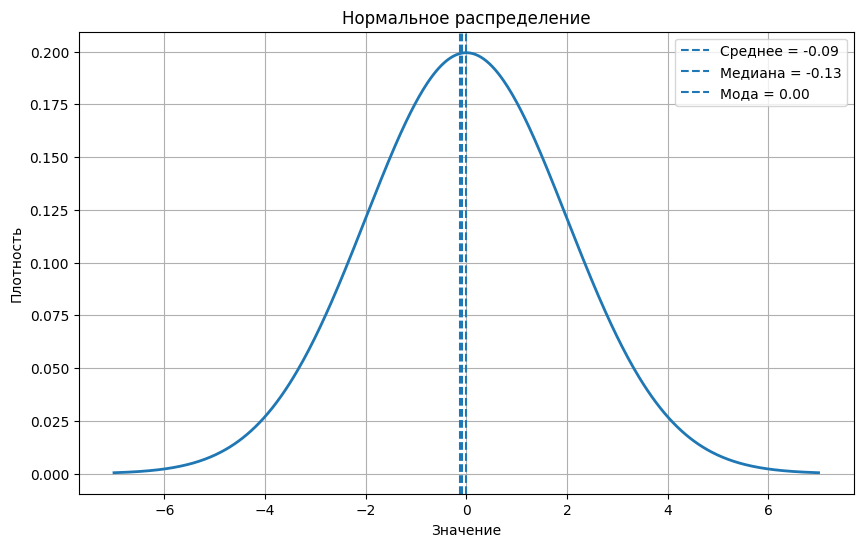

Среднее: -0.08717732184702016
Мода: 0
Медиана: -0.12606529871142363
Стандартное отклонение: 1.9984354634671098


In [ ]:
# нормальное распределение

normal_mean = 0
normal_std = 2

normal_data = np.random.normal(
    normal_mean,
    normal_std,
    n
)

normal_sample_mean = np.mean(normal_data)
normal_median = np.median(normal_data)
normal_sample_std = np.std(normal_data)

normal_mode = normal_mean

x_normal = np.linspace(
    -7,
    7,
    500
)

y_normal = stats.norm.pdf(
    x_normal,
    loc=normal_mean,
    scale=normal_std
)

plt.figure(figsize=(10, 6))

plt.plot(
    x_normal,
    y_normal,
    linewidth=2
)

plt.axvline(
    normal_sample_mean,
    linestyle='--',
    label=f'Среднее = {normal_sample_mean:.2f}'
)

plt.axvline(
    normal_median,
    linestyle='--',
    label=f'Медиана = {normal_median:.2f}'
)

plt.axvline(
    normal_mode,
    linestyle='--',
    label=f'Мода = {normal_mode:.2f}'
)

plt.title('Нормальное распределение')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)

plt.show()

print('Среднее:', normal_sample_mean)
print('Мода:', normal_mode)
print('Медиана:', normal_median)
print('Стандартное отклонение:', normal_sample_std)

Среднее, медиана и мода находятся примерно в одной точке, а большинство значений расположено около среднего.

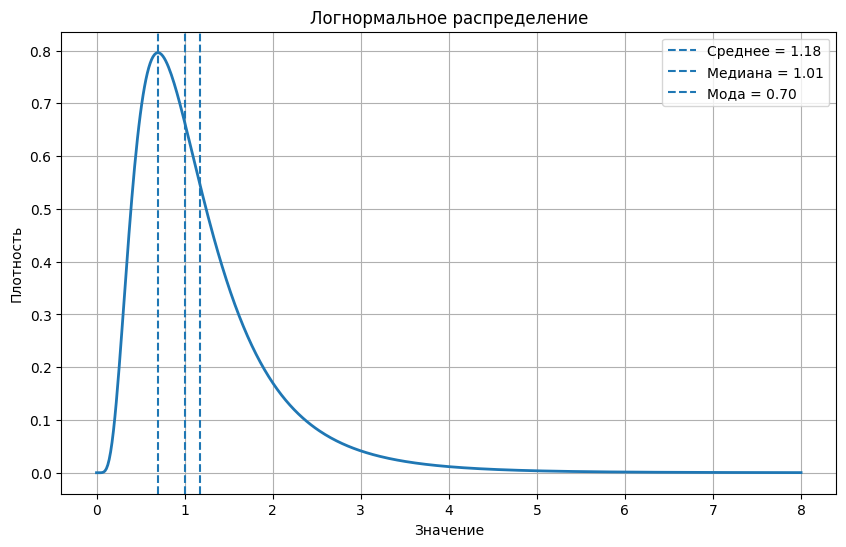

Среднее: 1.180547643712122
Мода: 0.697676326071031
Медиана: 1.0092226203377717
Стандартное отклонение: 0.7653239320210057


In [ ]:
# логнормальное распределение

lognormal_mean = 0
lognormal_sigma = 0.6

lognormal_data = np.random.lognormal(
    mean=lognormal_mean,
    sigma=lognormal_sigma,
    size=n
)

lognormal_sample_mean = np.mean(lognormal_data)
lognormal_median = np.median(lognormal_data)
lognormal_sample_std = np.std(lognormal_data)

lognormal_mode = np.exp(
    lognormal_mean - lognormal_sigma**2
)

x_lognormal = np.linspace(
    0,
    8,
    500
)

y_lognormal = stats.lognorm.pdf(
    x_lognormal,
    s=lognormal_sigma,
    scale=np.exp(lognormal_mean)
)

plt.figure(figsize=(10, 6))

plt.plot(
    x_lognormal,
    y_lognormal,
    linewidth=2
)

plt.axvline(
    lognormal_sample_mean,
    linestyle='--',
    label=f'Среднее = {lognormal_sample_mean:.2f}'
)

plt.axvline(
    lognormal_median,
    linestyle='--',
    label=f'Медиана = {lognormal_median:.2f}'
)

plt.axvline(
    lognormal_mode,
    linestyle='--',
    label=f'Мода = {lognormal_mode:.2f}'
)

plt.title('Логнормальное распределение')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)

plt.show()

print('Среднее:', lognormal_sample_mean)
print('Мода:', lognormal_mode)
print('Медиана:', lognormal_median)
print('Стандартное отклонение:', lognormal_sample_std)

Распределение несимметрично и имеет длинный хвост вправо. Большинство значений находится около небольших значений, при этом встречаются отдельные значительно большие значения.

Подумайте, в каких случаях медиана предпочтительнее среднего при расчете "средней температуры по больнице". Какие модификации можно было бы произвести для формулы среднего или для выборки, чтобы среднее значение стало более репрезентативно в подобных случаях? Напишите ответ.

Медиана предпочтительнее среднего, когда данные содержат выбросы или асимметричны. В примере с температурой по больнице один тяжелобольной пациент с температурой 40 °C сильно смещает среднее, но почти не влияет на медиану. Чтобы среднее стало репрезентативнее, можно использовать усечённое среднее (отбрасываем крайние 5–10% значений), можем заменить выбросы на граничные значения, взвешенное среднее (даём меньший вес аномалиям). Для мультипликативных величин (цены, доходы) полезно логарифмирование - тогда среднее логарифмов даёт геометрическое среднее, устойчивое к выбросам.

##2 (2 балла)

1000 человек бросают монетку. Каждый бросил 10 раз.

 1. Какова вероятность того, что хотя бы у одного человека монетка выпала 10 раз подряд той же самой стороной (орлом или решкой)?
 2. Какова вероятность того, что хотя бы у одного человека монетка выпала 8 раз подряд той же самой стороной (орлом или решкой)?
 3. Какова вероятность того, что ровно у троих человек из 1000 монетка выпала 10 раз подряд той же самой стороной (орлом или решкой)?

 Рассчитайте вероятности, а также смоделируйте ситуацию и оцените эмпирическое распределение.

p10 для одного человека = 0.001953125000
теоретическая вероятность = 0.858440454732
эмпирическая вероятность  = 0.855400
среднее X10 = 1.9664, теоретически = 1.9531


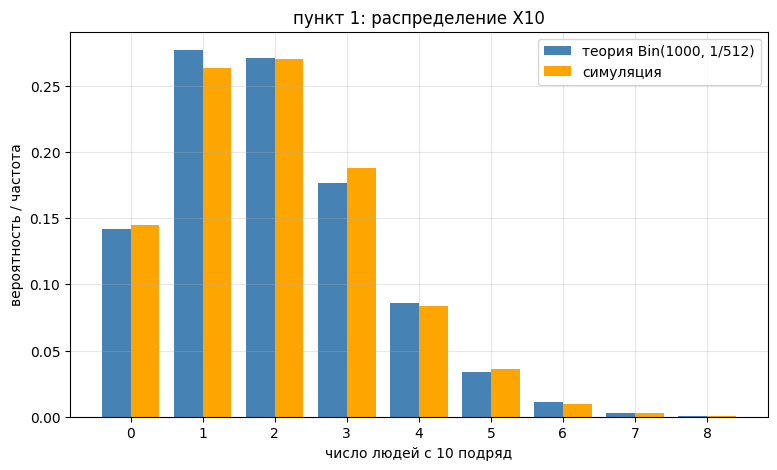

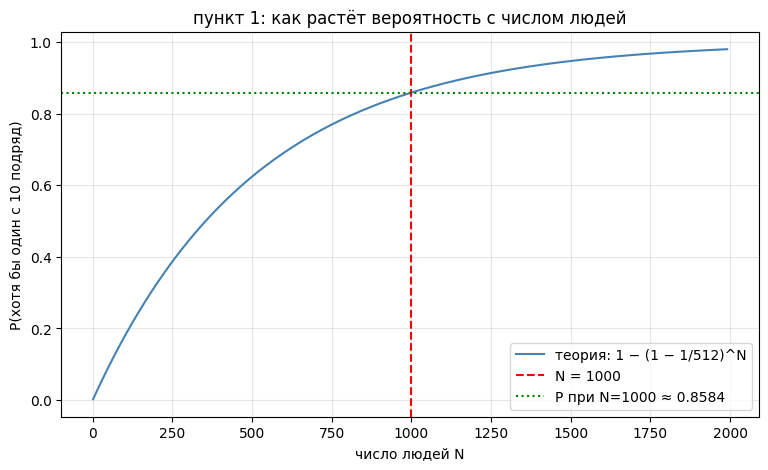

In [ ]:
# вероятность, что хотя бы у одного из 1000 человек выпало 10 подряд
# (либо все орлы, либо все решки)

from math import comb

N = 1000          # человек
n_toss = 10       # бросков на человека

# для одного человека: ровно 10 подряд = 2 последовательности из 1024
p10 = 2 / (2 ** 10)   # = 1/512
print(f"p10 для одного человека = {p10:.12f}")

# аналитически: 1 - (1 - p)^N
P1 = 1 - (1 - p10) ** N
print(f"теоретическая вероятность = {P1:.12f}")

# симуляция
rng = np.random.default_rng(2024)
n_sims = 5000

tosses = rng.integers(0, 2, size=(n_sims, N, n_toss), dtype=np.uint8)
sums = tosses.sum(axis=2)                  # если 0 или 10 — все броски одинаковые
X10 = ((sums == 0) | (sums == 10)).sum(axis=1)

print(f"эмпирическая вероятность  = {(X10 >= 1).mean():.6f}")
print(f"среднее X10 = {X10.mean():.4f}, теоретически = {N * p10:.4f}")


ks = np.arange(0, 9)
emp = np.array([(X10 == k).mean() for k in ks])
theor = np.array([comb(N, k) * (p10 ** k) * ((1 - p10) ** (N - k)) for k in ks])

width = 0.4
plt.figure(figsize=(9, 5))
plt.bar(ks - width/2, theor, width=width, label="теория Bin(1000, 1/512)", color="steelblue")
plt.bar(ks + width/2, emp,   width=width, label="симуляция", color="orange")
plt.xlabel("число людей с 10 подряд")
plt.ylabel("вероятность / частота")
plt.title("пункт 1: распределение X10")
plt.xticks(ks)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Ns = np.arange(1, 2001, 10)   # от 1 до 2000 человек
P_theory = 1 - (1 - p10) ** Ns

plt.figure(figsize=(9, 5))
plt.plot(Ns, P_theory, color="steelblue", label="теория: 1 − (1 − 1/512)^N")
plt.axvline(1000, color="red", linestyle="--", label="N = 1000")
plt.axhline(1 - (1 - p10) ** 1000, color="green", linestyle=":", label=f"P при N=1000 ≈ {1-(1-p10)**1000:.4f}")
plt.xlabel("число людей N")
plt.ylabel("P(хотя бы один с 10 подряд)")
plt.title("пункт 1: как растёт вероятность с числом людей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

p8 для одного человека = 0.015625000000
теоретическая вероятность = 0.999999855264
эмпирическая вероятность  = 1.000000
среднее X8 = 15.5664, теоретически = 15.6250


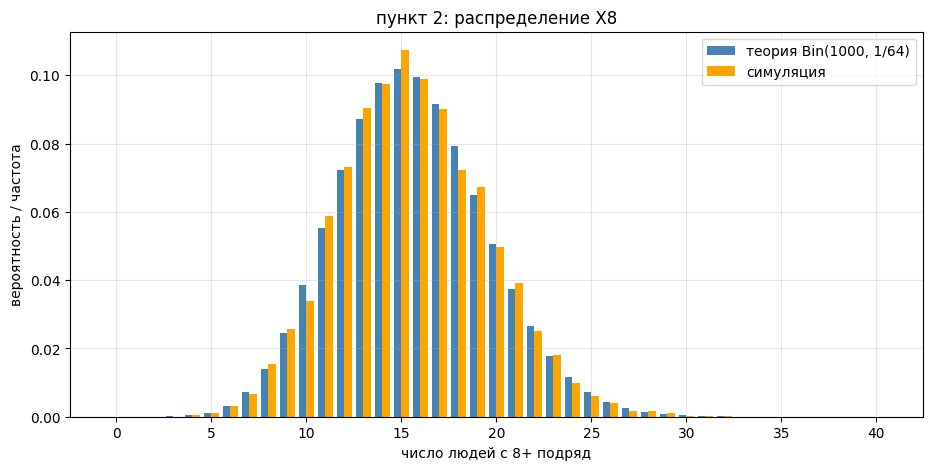

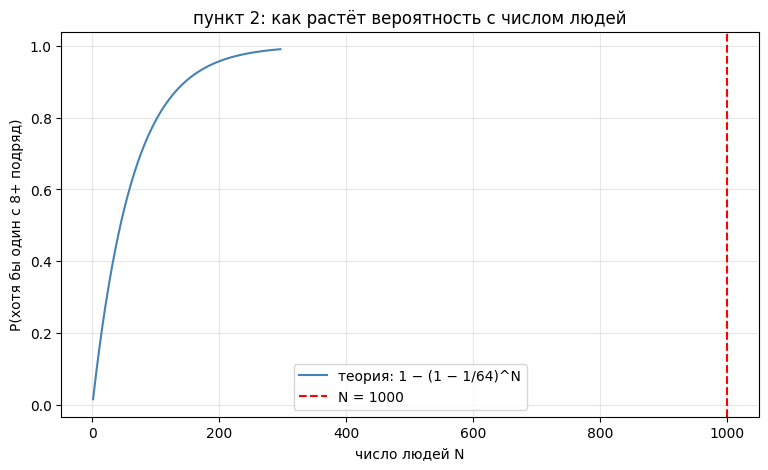

In [ ]:
# вероятность, что хотя бы у одного из 1000 человек выпало 8+ подряд
# (серия одинаковых исходов длины не меньше 8)

N = 1000
n_toss = 10

# для одного человека: 16 подходящих последовательностей из 1024
p8 = 16 / (2 ** 10)   # = 1/64
print(f"p8 для одного человека = {p8:.12f}")

# аналитически
P2 = 1 - (1 - p8) ** N
print(f"теоретическая вероятность = {P2:.12f}")

# симуляция
rng = np.random.default_rng(2024)
n_sims = 5000

tosses = rng.integers(0, 2, size=(n_sims, N, n_toss), dtype=np.uint8)

def max_run(arr, value):
    """максимальная длина серии равных value для каждого человека."""
    cur = np.zeros(arr.shape[:2], dtype=np.int16)
    mx = np.zeros_like(cur)
    for k in range(arr.shape[2]):
        cur = (cur + 1) * (arr[:, :, k] == value)
        mx = np.maximum(mx, cur)
    return mx

mx_heads = max_run(tosses, 1)
mx_tails = max_run(tosses, 0)
has8 = (mx_heads >= 8) | (mx_tails >= 8)
X8 = has8.sum(axis=1)

print(f"эмпирическая вероятность  = {(X8 >= 1).mean():.6f}")
print(f"среднее X8 = {X8.mean():.4f}, теоретически = {N * p8:.4f}")



# --- график 1: распределение X8 ---
# среднее ~15.6, значит строим от 0 до 40
ks = np.arange(0, 41)
emp = np.array([(X8 == k).mean() for k in ks])
theor = np.array([comb(N, k) * (p8 ** k) * ((1 - p8) ** (N - k)) for k in ks])

width = 0.4
plt.figure(figsize=(11, 5))
plt.bar(ks - width/2, theor, width=width, label="теория Bin(1000, 1/64)", color="steelblue")
plt.bar(ks + width/2, emp,   width=width, label="симуляция", color="orange")
plt.xlabel("число людей с 8+ подряд")
plt.ylabel("вероятность / частота")
plt.title("пункт 2: распределение X8")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# --- график 2: P(хотя бы один) как функция от N ---
Ns = np.arange(1, 301, 5)   # от 1 до 300 человек (там уже почти 1)
P_theory = 1 - (1 - p8) ** Ns

plt.figure(figsize=(9, 5))
plt.plot(Ns, P_theory, color="steelblue", label="теория: 1 − (1 − 1/64)^N")
plt.axvline(1000, color="red", linestyle="--", label="N = 1000")
plt.xlabel("число людей N")
plt.ylabel("P(хотя бы один с 8+ подряд)")
plt.title("пункт 2: как растёт вероятность с числом людей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

теоретическая P(X=3) = 0.176287385812
эмпирическая P(X=3)  = 0.188200


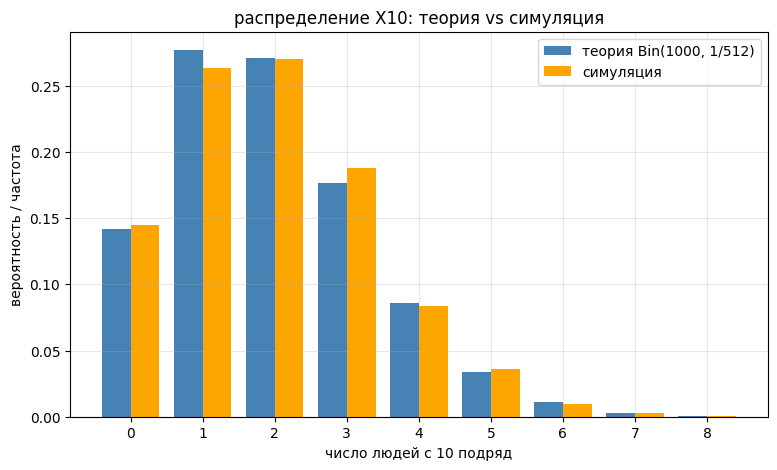


  k |       теория |    симуляция
----------------------------------
  0 |     0.141560 |     0.144600
  1 |     0.277025 |     0.263800
  2 |     0.270790 |     0.270600
  3 |     0.176287 |     0.188200
  4 |     0.085988 |     0.083800
  5 |     0.033520 |     0.036000
  6 |     0.010878 |     0.009800
  7 |     0.003023 |     0.002800
  8 |     0.000734 |     0.000400


In [ ]:
# вероятность, что ровно трое из 1000 человек выбросили 10 подряд
N = 1000
n_toss = 10

p10 = 2 / (2 ** 10)   # = 1/512

# аналитически: биномиальное распределение Bin(N, p10)
P3 = comb(N, 3) * (p10 ** 3) * ((1 - p10) ** (N - 3))
print(f"теоретическая P(X=3) = {P3:.12f}")

# симуляция
rng = np.random.default_rng(2024)
n_sims = 5000

tosses = rng.integers(0, 2, size=(n_sims, N, n_toss), dtype=np.uint8)
sums = tosses.sum(axis=2)
X10 = ((sums == 0) | (sums == 10)).sum(axis=1)

print(f"эмпирическая P(X=3)  = {(X10 == 3).mean():.6f}")

# эмпирическое распределение X10
ks = np.arange(0, 9)
emp = np.array([(X10 == k).mean() for k in ks])
theor = np.array([comb(N, k) * (p10 ** k) * ((1 - p10) ** (N - k)) for k in ks])

width = 0.4
plt.figure(figsize=(9, 5))
plt.bar(ks - width/2, theor, width=width, label="теория Bin(1000, 1/512)", color="steelblue")
plt.bar(ks + width/2, emp,   width=width, label="симуляция", color="orange")
plt.xlabel("число людей с 10 подряд")
plt.ylabel("вероятность / частота")
plt.title("распределение X10: теория vs симуляция")
plt.xticks(ks)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"\n{'k':>3} | {'теория':>12} | {'симуляция':>12}")
print("-" * 34)
for k in ks:
    print(f"{int(k):>3} | {theor[int(k)]:>12.6f} | {emp[int(k)]:>12.6f}")

##3

В магазин поступила новая продукция с трех предприятий. Процентный состав этой продукции следующий: 20% - продукция первого предприятия, 30% - продукция второго предприятия, 50% - продукция третьего предприятия; далее, 10% продукции первого предприятия высшего сорта, на втором предприятии - 5% и на третьем - 20% продукции высшего сорта. Найти вероятность того, что случайно купленная новая продукция окажется высшего сорта. Если известно, что купленная продукция высшего сорта, какова вероятность, что она была куплена на втором предприятии?

Решите задачу в общем случае для N предприятий, где доля продукции каждого составляет $a_i$, а доля продукции высшего сорта на каждом составляет $b_i$. Напишите функцию, принимающую на вход два списка: a и b, а также n - номер предприятия, для которого необходимо узнать вероятность, что продукция высшего сорта была куплена именно на нём (нумерация с единицы). Функция должна возвращать две вероятности.

In [ ]:
def quality_probabilities(a, b, n):
    """
    a : список долей продукции предприятий (сумма должна быть 1)
    b : список долей продукции высшего сорта на каждом предприятии
    n : номер предприятия (нумерация с единицы)

    возвращает (P(A), P(H_n | A))
    """
    # проверка, что длины списков совпадают
    if len(a) != len(b):
        raise ValueError("списки a и b должны быть одинаковой длины")

    # проверка корректности номера предприятия
    if not (1 <= n <= len(a)):
        raise ValueError(f"номер предприятия должен быть от 1 до {len(a)}")

    # полная вероятность: сумма a_i * b_i по всем предприятиям
    P_A = sum(a[i] * b[i] for i in range(len(a)))

    # апостериорная вероятность для предприятия n (индекс n-1 в списке)
    P_Hn_given_A = a[n - 1] * b[n - 1] / P_A

    return P_A, P_Hn_given_A

In [ ]:
a = [0.20, 0.30, 0.50]
b = [0.10, 0.05, 0.20]

P_A, P_H2 = quality_probabilities(a, b, 2)

print(f"P(A) = {P_A:.4f}")              # 0.1350
print(f"P(H2|A) = {P_H2:.4f}")          # 0.1111

P(A) = 0.1350
P(H2|A) = 0.7407


In [ ]:
def check_posteriors_sum_to_one(a, b):
    """
    проверяем, что сумма всех апостериорных вероятностей = 1.
    это должно быть так, потому что гипотезы образуют полную группу.
    """
    P_A = sum(a[i] * b[i] for i in range(len(a)))
    posteriors = [a[i] * b[i] / P_A for i in range(len(a))]
    total = sum(posteriors)
    return posteriors, total


#  проверка на задаче с тремя предприятиями
a = [0.20, 0.30, 0.50]
b = [0.10, 0.05, 0.20]

P_A, P_H2 = quality_probabilities(a, b, 2)
print(f"P(A)     = {P_A:.6f}")
print(f"P(H2|A)  = {P_H2:.6f}")
print()

posteriors, total = check_posteriors_sum_to_one(a, b)

print("апостериорные вероятности по предприятиям:")
for i, p in enumerate(posteriors, start=1):
    print(f"  P(H{i}|A) = {p:.6f}")

print(f"\nсумма всех P(Hi|A) = {total:.12f}")
print(f"отклонение от 1   = {abs(total - 1):.2e}")

#  проверка на большом случайном примере

rng = np.random.default_rng(42)
N = 10
a_random = rng.dirichlet(np.ones(N))    # случайные доли, сумма = 1
b_random = rng.uniform(0.01, 0.30, size=N)

P_A_r, _ = quality_probabilities(a_random, b_random, 1)
posteriors_r, total_r = check_posteriors_sum_to_one(a_random, b_random)

print(f"\nслучайный пример с N = {N}:")
print(f"  P(A)              = {P_A_r:.6f}")
print(f"  сумма P(Hi|A)     = {total_r:.12f}")
print(f"  отклонение от 1   = {abs(total_r - 1):.2e}")

P(A)     = 0.135000
P(H2|A)  = 0.111111

апостериорные вероятности по предприятиям:
  P(H1|A) = 0.148148
  P(H2|A) = 0.111111
  P(H3|A) = 0.740741

сумма всех P(Hi|A) = 1.000000000000
отклонение от 1   = 0.00e+00

случайный пример с N = 10:
  P(A)              = 0.146990
  сумма P(Hi|A)     = 1.000000000000
  отклонение от 1   = 2.22e-16


# Методы оптимизации (3 балла)



(Задание взято у Яндекса)

Дана функция $f(x) = (a\sin(x) + b\ln(x))^2 + cx^2$ и файл, содержащий пары (x, f(x)). Необходимо с точностью до трёх знаков после запятой подобрать коэффициенты a, b, c исходной функции. Для решения задачи предлагается использовать градиентный спуск и функцию потерь MSE.

P.S. на предоставленном наборе данных возможно получить MSE < 0.00001, ориентируйтесь на эту цифру.

In [ ]:
!gdown 1P5REbDVMtoHk_EPOaXzFWym2sMKhhbg3

Downloading...
From: https://drive.google.com/uc?id=1P5REbDVMtoHk_EPOaXzFWym2sMKhhbg3
To: /content/data.txt
100% 27.0k/27.0k [00:00<00:00, 3.10MB/s]


In [ ]:
with open('data.txt', 'r') as file:
    x_data = []
    y_data = []
    for para in eval(file.read()):
        x_data.append(para[0])
        y_data.append(para[1])
x_data = np.array(x_data)
y_data = np.array(y_data)

iter     0: MSE = 1230.201471, a=1.050000, b=1.050000, c=1.050000
iter  1000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  2000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  3000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  4000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  5000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  6000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  7000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  8000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter  9000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 10000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 11000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 12000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 13000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 14000: MSE = 0.000000, a=3.141620, b=2.718370, c=3.999970
iter 15000: MSE = 0.000000, a=3.141620, b=2.718370, 

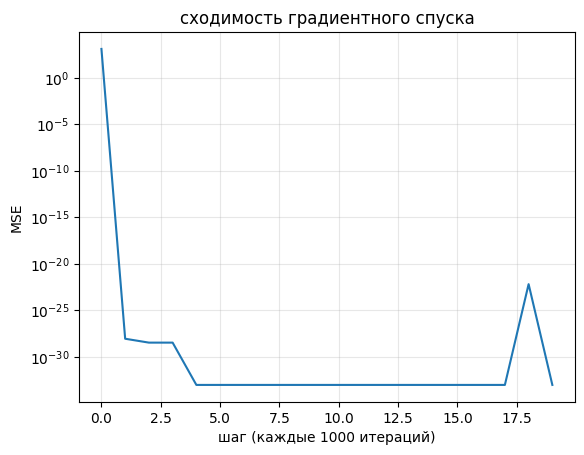

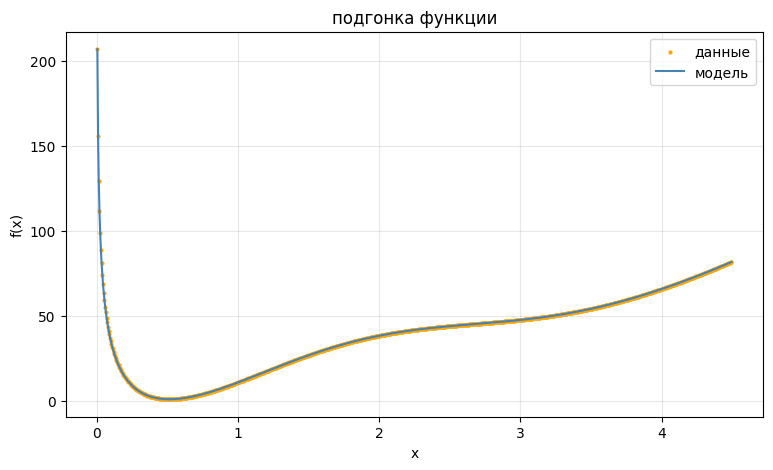

In [ ]:
# модель
# f(x) = (a*sin(x) + b*ln(x))^2 + c*x^2
# обозначим u = a*sin(x) + b*ln(x), тогда f = u^2 + c*x^2

def model(x, a, b, c):
    u = a * np.sin(x) + b * np.log(x)
    return u**2 + c * x**2

# функция потерь MSE
def mse(y_pred, y_true):
    return np.mean((y_pred - y_true)**2)

# градиенты по a, b, c
# dL/da = (4/N) * sum( (f - y) * u * sin(x) )
# dL/db = (4/N) * sum( (f - y) * u * ln(x)  )
# dL/dc = (2/N) * sum( (f - y) * x^2        )
def gradients(x, y, a, b, c):
    u = a * np.sin(x) + b * np.log(x)
    f = u**2 + c * x**2
    err = f - y
    N = len(x)
    da = (4 / N) * np.sum(err * u * np.sin(x))
    db = (4 / N) * np.sum(err * u * np.log(x))
    dc = (2 / N) * np.sum(err * x**2)
    return da, db, dc

# начальные приближения
a, b, c = 1.0, 1.0, 1.0

# параметры оптимизатора Adam
lr = 0.05
beta1, beta2 = 0.9, 0.999
eps = 1e-8
m = np.zeros(3)   # первая моментная оценка
v = np.zeros(3)   # вторая моментная оценка
t = 0

losses = []

# цикл градиентного спуска
for i in range(20000):
    t += 1
    da, db, dc = gradients(x_data, y_data, a, b, c)
    grad = np.array([da, db, dc])

    # обновление моментов (Adam)
    m = beta1 * m + (1 - beta1) * grad
    v = beta2 * v + (1 - beta2) * grad**2
    m_hat = m / (1 - beta1**t)
    v_hat = v / (1 - beta2**t)

    # шаг
    a -= lr * m_hat[0] / (np.sqrt(v_hat[0]) + eps)
    b -= lr * m_hat[1] / (np.sqrt(v_hat[1]) + eps)
    c -= lr * m_hat[2] / (np.sqrt(v_hat[2]) + eps)

    if i % 1000 == 0:
        loss = mse(model(x_data, a, b, c), y_data)
        losses.append(loss)
        print(f"iter {i:5d}: MSE = {loss:8f}, a={a:.6f}, b={b:.6f}, c={c:.6f}")

# результат
y_pred = model(x_data, a, b, c)
final_mse = mse(y_pred, y_data)

print(f"\nFinal MSE = {final_mse:.8f}")
print(f"a = {a:.3f}, b = {b:.3f}, c = {c:.3f}")

# график сходимости
plt.plot(losses)
plt.yscale('log')
plt.xlabel('шаг (каждые 1000 итераций)')
plt.ylabel('MSE')
plt.title('сходимость градиентного спуска')
plt.grid(alpha=0.3)
plt.show()

# график подгонки
plt.figure(figsize=(9, 5))
plt.scatter(x_data, y_data, s=4, label='данные', color='orange')
plt.plot(x_data, y_pred, color='steelblue', label='модель')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('подгонка функции')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

В ходе работы были освоены основные приёмы численного анализа, линейной алгебры, теории вероятностей и оптимизации на Python. Реализованы: построение графиков функций и производных, работа с SymPy, матричные шаблоны без циклов, операции с тензорами в PyTorch, визуализация распределений, задачи на формулу полной вероятности и Байеса, а также подбор коэффициентов функции градиентным спуском с оптимизатором Adam. Все аналитические результаты подтверждены моделированием, расхождения - в пределах статистической погрешности. Освоены NumPy, SymPy, PyTorch и Matplotlib.